In [1]:
# Análise exploratória dos dados (Tela 1 e Tela 2)

import json
import pandas as pd      # criar e mexer em tabelas
import numpy as np       # fazer contas com muitos números de uma vez
import seaborn as sns    # fazer gráficos bonitos com pouco código
import matplotlib.pyplot as plt  # a base para desenhar gráficos

# Carrega o arquivo limpo, gerado no notebook de limpeza
with open("../dados/processados/inct_limpo.json", encoding="utf-8") as arquivo:
    dados_limpos = json.load(arquivo)

# Monta a tabela a partir do JSON. Cada linha representa um bairro em um nível do rio.
df = pd.DataFrame(dados_limpos)

# Mostra o tamanho da tabela e as cinco primeiras linhas, para verificar se o arquivo foi carregado corretamente
print(df.shape)   # o esperado são 6674 linhas e 11 colunas
df.head()

(6674, 11)


,nivel,bairro,affected_buildings,total_buildings,percentage,population,affected_population,corrigido,affected_buildings_original,percentage_original,affected_population_original
0,3.0,Aberta dos Morros,0,4696,0.000000,9854,0,False,0,0,0
1,3.0,Agronomia,0,1771,0.000000,2677,0,False,0,0,0
2,3.0,Anchieta,28,589,4.753820,791,37,False,28,5,40
3,3.0,Arquipélago,4685,4688,99.936007,6411,6406,False,4685,100,6411
4,3.0,Auxiliadora,0,1995,0.000000,8909,0,False,0,0,0


Pessoas afetadas com o rio a 3.0 metros: 32106
Pessoas afetadas com o rio a 5.3 metros: 136373
Pessoas afetadas com o rio a 10.0 metros: 271853
O ponto vermelho marca o nivel 5.3, o mais proximo do recorde de 5,35 metros da enchente de 2024


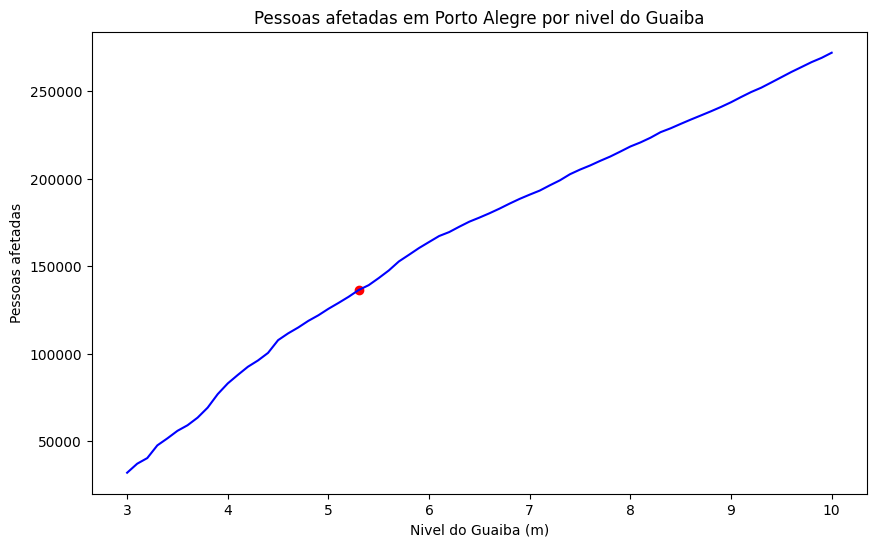

In [2]:
# Gráfico 1: pessoas afetadas em toda a cidade, em cada nível do rio
# Soma as pessoas afetadas de todos os bairros, separadamente para cada nível
pessoas_por_nivel = df.groupby("nivel")["affected_population"].sum()

print("Pessoas afetadas com o rio a 3.0 metros:", pessoas_por_nivel.loc[3.0])
print("Pessoas afetadas com o rio a 5.3 metros:", pessoas_por_nivel.loc[5.3])
print("Pessoas afetadas com o rio a 10.0 metros:", pessoas_por_nivel.loc[10.0])
print("O ponto vermelho marca o nivel 5.3, o mais proximo do recorde de 5,35 metros da enchente de 2024")

plt.figure(figsize=(10,6))
pessoas_por_nivel.plot(color="blue")
plt.scatter(5.3, pessoas_por_nivel.loc[5.3], color="red")   # marca o nível 5.3 no gráfico
plt.title("Pessoas afetadas em Porto Alegre por nivel do Guaiba")
plt.xlabel("Nivel do Guaiba (m)")
plt.ylabel("Pessoas afetadas")
plt.show()

# O que o gráfico mostra: o número de pessoas afetadas cresce sem parar conforme o rio sobe.
# Com o rio a 3 metros, são cerca de 32 mil pessoas. No nível 5,3, o mais próximo da enchente de 2024,
# são cerca de 136 mil pessoas, perto de 10% da população da cidade. Com o rio a 10 metros, passam de 270 mil.
# Em média, cada metro a mais de água atinge cerca de 34 mil pessoas a mais.

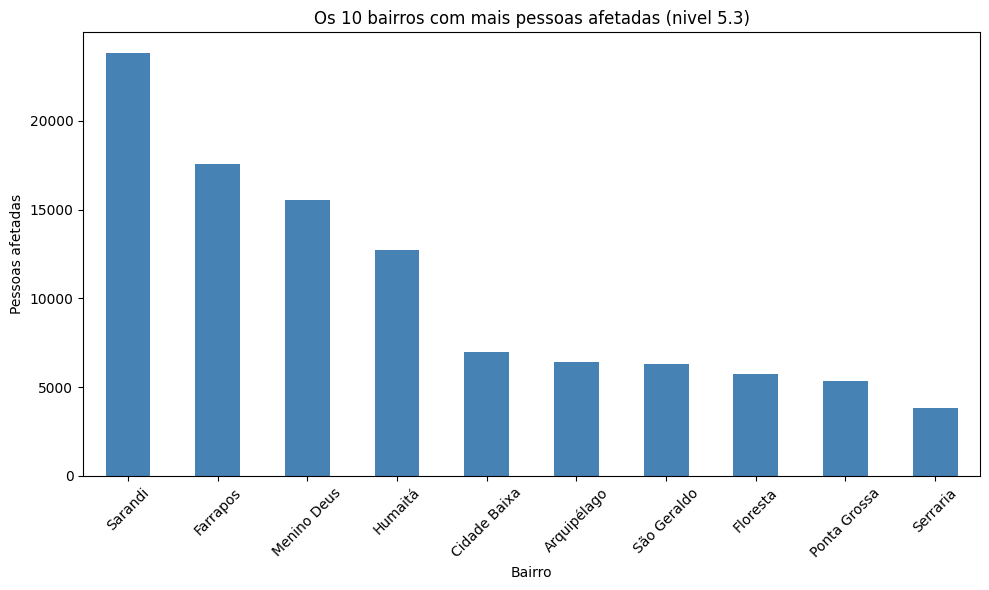

In [3]:
# Gráfico 2: ranking dos 10 bairros com mais pessoas afetadas no nível 5.3, o mais próximo da enchente de 2024
nivel_5_3 = df[df["nivel"] == 5.3]                                              # separa as linhas do nível 5.3
pessoas_por_bairro = nivel_5_3.groupby("bairro")["affected_population"].sum()  # pessoas afetadas em cada bairro
ranking = pessoas_por_bairro.sort_values(ascending=False).iloc[0:10]           # ordena do maior para o menor e pega os 10 primeiros

plt.figure(figsize=(10,6))
ranking.plot(kind="bar", color="steelblue")
plt.title("Os 10 bairros com mais pessoas afetadas (nivel 5.3)")
plt.xlabel("Bairro")
plt.ylabel("Pessoas afetadas")
plt.xticks(rotation=45)   # inclina os nomes dos bairros para não ficarem um em cima do outro
plt.tight_layout()
plt.show()

# O que o gráfico mostra: no nível 5,3, o Sarandi é o bairro com mais pessoas afetadas, cerca de 24 mil,
# seguido de Farrapos e Menino Deus. O Sarandi lidera por ser um bairro muito populoso,
# mesmo com menos da metade dos prédios alagados. Já Farrapos e Humaitá aparecem no topo porque ficam totalmente alagados.

Bairros atingidos no nivel 5.3: 36


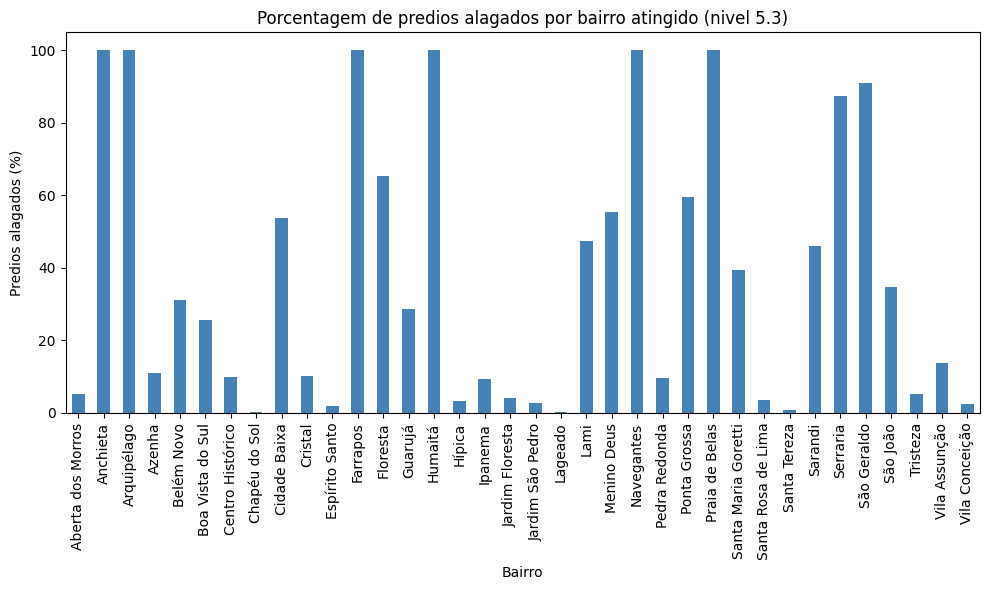

In [4]:
# Gráfico 3: porcentagem de prédios alagados em cada bairro atingido, no nível 5.3
bairros_atingidos = nivel_5_3[nivel_5_3["percentage"] > 0]                         # só os bairros com pelo menos um prédio alagado
porcentagem_por_bairro = bairros_atingidos.groupby("bairro")["percentage"].sum()   # porcentagem de prédios alagados de cada bairro

print("Bairros atingidos no nivel 5.3:", bairros_atingidos.shape[0])

plt.figure(figsize=(10,6))
porcentagem_por_bairro.plot(kind="bar", color="steelblue")
plt.title("Porcentagem de predios alagados por bairro atingido (nivel 5.3)")
plt.xlabel("Bairro")
plt.ylabel("Predios alagados (%)")
plt.xticks(rotation=90)   # deixa os nomes dos bairros na vertical, porque são muitos
plt.tight_layout()
plt.show()

# O que o gráfico mostra: no nível 5,3, 36 dos 94 bairros têm prédios alagados.
# Seis bairros ficam completamente alagados (Anchieta, Arquipélago, Farrapos, Humaitá, Navegantes e Praia de Belas)
# e o São Geraldo passa de 90%. Por outro lado, 14 bairros têm menos de 10% dos prédios alagados.
# Ou seja, o impacto é muito forte em poucos bairros e pequeno na maioria dos outros.

Bairros atingidos com o rio a 3.0 metros: 24
Bairros atingidos com o rio a 5.3 metros: 36
Bairros atingidos com o rio a 10.0 metros: 54


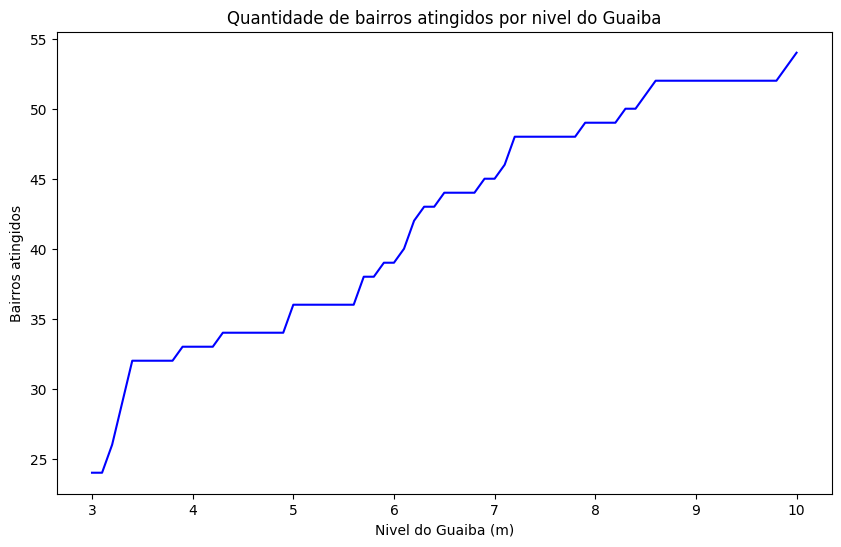

In [5]:
# Gráfico 4: quantidade de bairros atingidos em cada nível do rio
# Conta, para cada nível, quantos bairros têm pelo menos um prédio alagado
bairros_por_nivel = df[df["affected_buildings"] > 0]["nivel"].value_counts().sort_index()

print("Bairros atingidos com o rio a 3.0 metros:", bairros_por_nivel.loc[3.0])
print("Bairros atingidos com o rio a 5.3 metros:", bairros_por_nivel.loc[5.3])
print("Bairros atingidos com o rio a 10.0 metros:", bairros_por_nivel.loc[10.0])

plt.figure(figsize=(10,6))
bairros_por_nivel.plot(color="blue")
plt.title("Quantidade de bairros atingidos por nivel do Guaiba")
plt.xlabel("Nivel do Guaiba (m)")
plt.ylabel("Bairros atingidos")
plt.show()

# O que o gráfico mostra: já com o rio a 3 metros, 24 bairros têm prédios alagados.
# No nível 5,3 são 36 bairros, e com o rio a 10 metros chegam a 54, mais da metade dos 94 bairros da cidade.
# A quantidade de bairros cresce bem mais devagar do que a de pessoas: depois de certo nível,
# a água avança principalmente dentro dos bairros que já estavam atingidos.

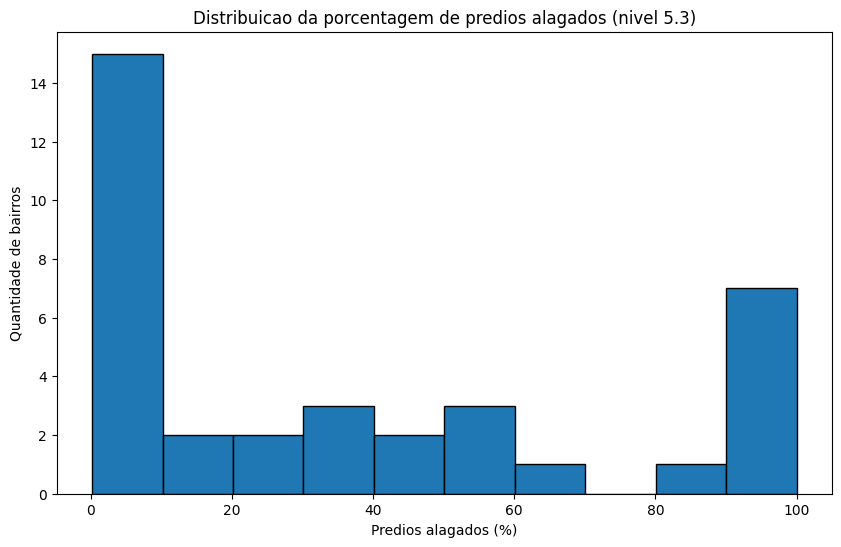

In [6]:
# Gráfico 5: distribuição da porcentagem de prédios alagados entre os bairros atingidos, no nível 5.3
# Mostra quantos bairros ficam em cada faixa de porcentagem (de 0 a 10%, de 10 a 20%, e assim por diante)
plt.figure(figsize=(10,6))
plt.hist(bairros_atingidos["percentage"], bins=10, edgecolor="black")
plt.title("Distribuicao da porcentagem de predios alagados (nivel 5.3)")
plt.xlabel("Predios alagados (%)")
plt.ylabel("Quantidade de bairros")
plt.show()

# O que o gráfico mostra: a maior parte dos bairros atingidos fica na primeira faixa, com menos de 10% dos prédios alagados,
# e existe outro grupo no extremo oposto, com mais de 90%. Os outros bairros ficam espalhados pelas faixas do meio.
# Isso mostra que a enchente não atinge os bairros de forma parecida: muitos são atingidos pouco e alguns quase por inteiro.

In [7]:
# Tela 2: o que as outras bases acrescentam à simulação do INCT

# Carrega a tabela da UFRGS com os municípios atingidos pela enchente de maio de 2024
ufrgs = pd.read_csv("../dados/originais/ufrgs_municipios_2024.csv")
print(ufrgs.shape)   # o esperado são 139 municípios e 26 colunas

# Verifica se existem valores vazios ou municípios repetidos nas colunas usadas nos gráficos
colunas_usadas = ["NM_MUN", "Pessoas_afetadas", "Pessoas_%", "Pessoas_2022", "Estabelecim_Ensino_Afetados_Diretamente", "Estabelecim_Saude_Afetados_Diretamente"]
print(ufrgs[colunas_usadas].isnull().sum())
print("Municipios repetidos:", ufrgs["NM_MUN"].duplicated().sum())

# Mostra a linha que tem valor vazio.
# O município de Victor Graeff não tem a informação de escolas e unidades de saúde. O valor fica vazio,
# porque preencher com zero seria afirmar que nenhuma escola foi atingida, sem ter essa informação.
ufrgs[ufrgs["Estabelecim_Ensino_Afetados_Diretamente"].isnull()][colunas_usadas]

(139, 26)
NM_MUN                                     0
Pessoas_afetadas                           0
Pessoas_%                                  0
Pessoas_2022                               0
Estabelecim_Ensino_Afetados_Diretamente    1
Estabelecim_Saude_Afetados_Diretamente     1
dtype: int64
Municipios repetidos: 0


,NM_MUN,Pessoas_afetadas,Pessoas_%,Pessoas_2022,Estabelecim_Ensino_Afetados_Diretamente,Estabelecim_Saude_Afetados_Diretamente
84,Victor Graeff,26,0.9,2780,NaN,NaN


In [8]:
# Carrega a população do IBGE e confere se ela é a mesma usada pela UFRGS
with open("../dados/originais/ibge_populacao_rs_2022.json", encoding="utf-8") as arquivo:
    ibge = pd.DataFrame(json.load(arquivo))

# No IBGE, o nome vem com " - RS" no final (por exemplo, "Canoas - RS").
# O final é removido para o nome ficar igual ao da tabela da UFRGS.
ibge["municipio"] = ibge["municipio"].apply(lambda nome: nome.removesuffix(" - RS"))

# Monta uma lista de consulta: para cada município, a população do IBGE
populacao_ibge = {}
for posicao in range(ibge.shape[0]):
    populacao_ibge[ibge["municipio"][posicao]] = ibge["populacao_2022"][posicao]

# Coloca a população do IBGE ao lado de cada município da UFRGS e compara
ufrgs["populacao_ibge"] = ufrgs["NM_MUN"].apply(lambda municipio: populacao_ibge[municipio])
diferentes = ufrgs[ufrgs["Pessoas_2022"] != ufrgs["populacao_ibge"]]
# Só o município de Putinga tem uma pequena diferença (3650 na UFRGS e 3747 no IBGE).
# Nas contas por habitante é usada a população do IBGE, que é a fonte oficial.
print("Municipios com populacao diferente:", diferentes.shape[0])
diferentes[["NM_MUN", "Pessoas_2022", "populacao_ibge"]]

Municipios com populacao diferente: 1


,NM_MUN,Pessoas_2022,populacao_ibge
135,Putinga,3650,3747


Total de pessoas atingidas na regiao do Guaiba: 632669


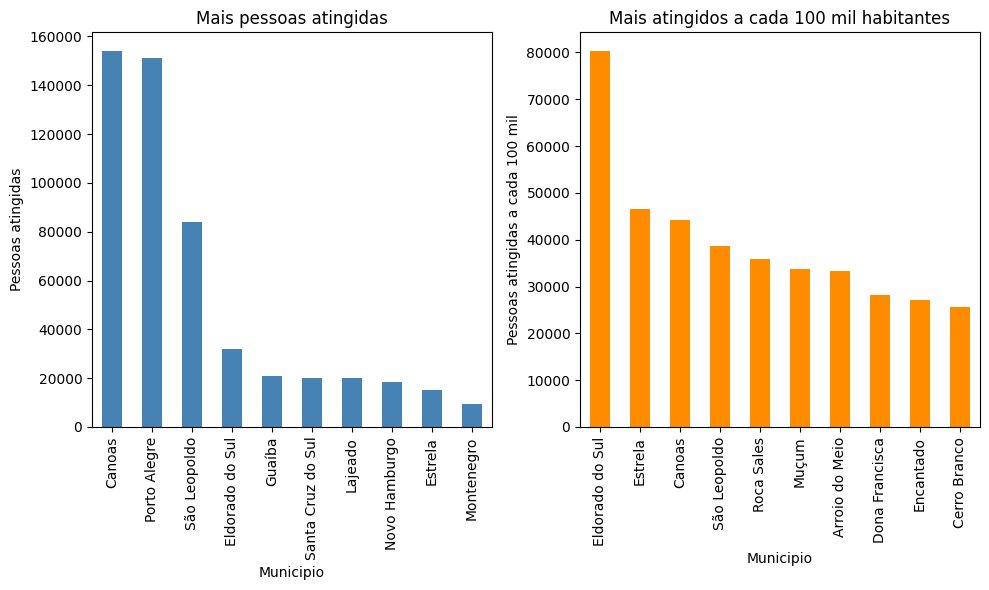

In [9]:
# Calcula as pessoas atingidas a cada 100 mil habitantes, usando a população oficial do IBGE.
# Essa conta permite comparar uma cidade grande com uma cidade pequena de forma justa.
ufrgs["atingidos_por_100_mil"] = ufrgs["Pessoas_afetadas"] / ufrgs["populacao_ibge"] * 100000

# Gráfico 6: os 10 municípios com mais pessoas atingidas, em número e a cada 100 mil habitantes
mais_pessoas = ufrgs.groupby("NM_MUN")["Pessoas_afetadas"].sum().sort_values(ascending=False).iloc[0:10]
mais_por_100_mil = ufrgs.groupby("NM_MUN")["atingidos_por_100_mil"].sum().sort_values(ascending=False).iloc[0:10]

print("Total de pessoas atingidas na regiao do Guaiba:", ufrgs["Pessoas_afetadas"].sum())

plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
mais_pessoas.plot(kind="bar", color="steelblue")
plt.title("Mais pessoas atingidas")
plt.xlabel("Municipio")
plt.ylabel("Pessoas atingidas")
plt.xticks(rotation=90)

plt.subplot(1,2,2)
mais_por_100_mil.plot(kind="bar", color="darkorange")
plt.title("Mais atingidos a cada 100 mil habitantes")
plt.xlabel("Municipio")
plt.ylabel("Pessoas atingidas a cada 100 mil")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# O que o gráfico mostra: na região do Guaíba, cerca de 633 mil pessoas foram atingidas em maio de 2024.
# Em número de pessoas, Canoas e Porto Alegre aparecem quase empatadas, com mais de 150 mil cada.
# Mas, quando a comparação é feita a cada 100 mil habitantes, Porto Alegre sai da lista e aparecem cidades menores:
# em Eldorado do Sul, cerca de 80% dos moradores foram atingidos. Em Porto Alegre, foram cerca de 11%.

Escolas atingidas na regiao: 806.0
Unidades de saude atingidas na regiao: 712.0


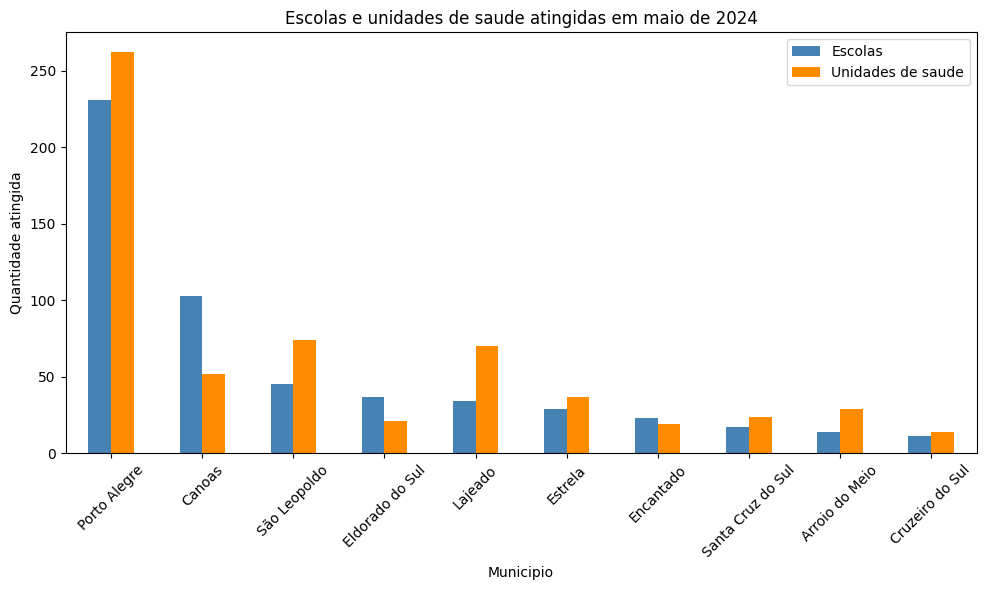

In [10]:
# Gráfico 7: escolas e unidades de saúde atingidas, nos 10 municípios com mais escolas atingidas
servicos = ufrgs.groupby("NM_MUN")[["Estabelecim_Ensino_Afetados_Diretamente", "Estabelecim_Saude_Afetados_Diretamente"]].sum()
servicos.columns = ["Escolas", "Unidades de saude"]   # nomes mais curtos para a legenda do gráfico
mais_servicos = servicos.sort_values("Escolas", ascending=False).iloc[0:10]

print("Escolas atingidas na regiao:", servicos["Escolas"].sum())
print("Unidades de saude atingidas na regiao:", servicos["Unidades de saude"].sum())

mais_servicos.plot(kind="bar", figsize=(10,6), color=["steelblue", "darkorange"])
plt.title("Escolas e unidades de saude atingidas em maio de 2024")
plt.xlabel("Municipio")
plt.ylabel("Quantidade atingida")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# O que o gráfico mostra: além das pessoas, a enchente atingiu 806 escolas e 712 unidades de saúde na região do Guaíba.
# Porto Alegre é o município com mais serviços atingidos: 231 escolas e 262 unidades de saúde,
# bem mais do que Canoas, que tem um número parecido de pessoas atingidas.

In [11]:
# Carrega as medições do nível do Guaíba na estação do Cais Mauá (ANA), feitas a cada 15 minutos
with open("../dados/originais/ana_nivel_cais_maua.json", encoding="utf-8") as arquivo:
    ana = pd.DataFrame(json.load(arquivo))

ana["nivel_m"] = ana["nivel_cm"] / 100   # converte o nível de centímetros para metros, como na simulação do INCT
print(ana.shape)
print("Medicoes repetidas:", ana["data_hora"].duplicated().sum())
print(ana["nivel_m"].describe())

# O sensor às vezes registra medições isoladas erradas, muito diferentes das vizinhas.
# Para evitar esse ruído, cada dia é representado pela mediana das suas medições.
ana["dia"] = ana["data_hora"].apply(lambda data: data[:10])   # pega só a data, sem o horário
nivel_por_dia = ana.groupby("dia")["nivel_m"].median()

print("Maior medicao isolada:", ana["nivel_m"].describe()["max"])
print("Maior mediana diaria:", nivel_por_dia.describe()["max"])
print("Dias com o rio acima de 3 metros:")
print(nivel_por_dia[nivel_por_dia >= 3])

(293709, 3)
Medicoes repetidas: 0
count    293709.000000
mean          1.033553
std           0.489692
min           0.030000
25%           0.710000
50%           0.950000
75%           1.240000
max           3.900000
Name: nivel_m, dtype: float64
Maior medicao isolada: 3.9
Maior mediana diaria: 3.42
Dias com o rio acima de 3 metros:
dia
2023-09-27    3.080
2023-11-20    3.125
2023-11-21    3.420
2023-11-22    3.275
2025-06-25    3.000
Name: nivel_m, dtype: float64


Atencao: a estacao parou de medir em 2 de maio de 2024, antes do pico de 5,35 metros


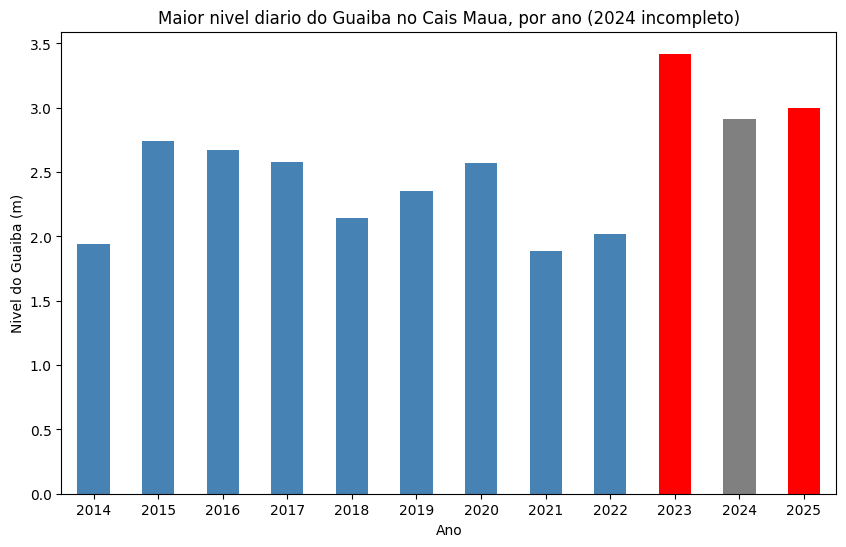

In [12]:
# Gráfico 8: maior nível do Guaíba em cada ano, de 2014 a 2025
# Separa o ano de cada dia e pega o maior nível diário de cada ano
dias = pd.DataFrame({"dia": nivel_por_dia.index, "nivel_m": nivel_por_dia.values})
dias["ano"] = dias["dia"].apply(lambda data: data[:4])
maior_nivel_por_ano = dias.groupby("ano")["nivel_m"].describe()["max"]

# Os anos em que o rio passou de 3 metros, onde a simulação do INCT começa, ficam em vermelho
# O ano de 2024 fica em cinza, porque a estação parou de medir antes do pico da enchente
cores = np.where(maior_nivel_por_ano.index == "2024", "gray", np.where(maior_nivel_por_ano >= 3, "red", "steelblue"))

print("Atencao: a estacao parou de medir em 2 de maio de 2024, antes do pico de 5,35 metros")

plt.figure(figsize=(10,6))
maior_nivel_por_ano.plot(kind="bar", color=cores)
plt.title("Maior nivel diario do Guaiba no Cais Maua, por ano (2024 incompleto)")
plt.xlabel("Ano")
plt.ylabel("Nivel do Guaiba (m)")
plt.xticks(rotation=0)
plt.show()

# O que o gráfico mostra: de 2014 a 2022, o Guaíba nunca passou de 3 metros no Cais Mauá, o nível onde a simulação do INCT começa.
# Isso aconteceu pela primeira vez na série em 2023 (3,08 m em setembro e 3,42 m em novembro), de novo em 2025 (3,00 m em junho),
# e em 2024, quando o rio chegou a 5,35 m. Mas a estação parou de medir em 2 de maio de 2024, e por isso o pico não aparece no gráfico.
# Os níveis da simulação do INCT, que antes eram raros, passaram a acontecer com mais frequência nos últimos anos.

Simulacao do INCT (nivel 5.3)      136373
Observado pela UFRGS (6/5/2024)    151141
dtype: int64
nivel
5.5    143228
5.6    147565
5.7    152708
5.8    156500
Name: affected_population, dtype: int64


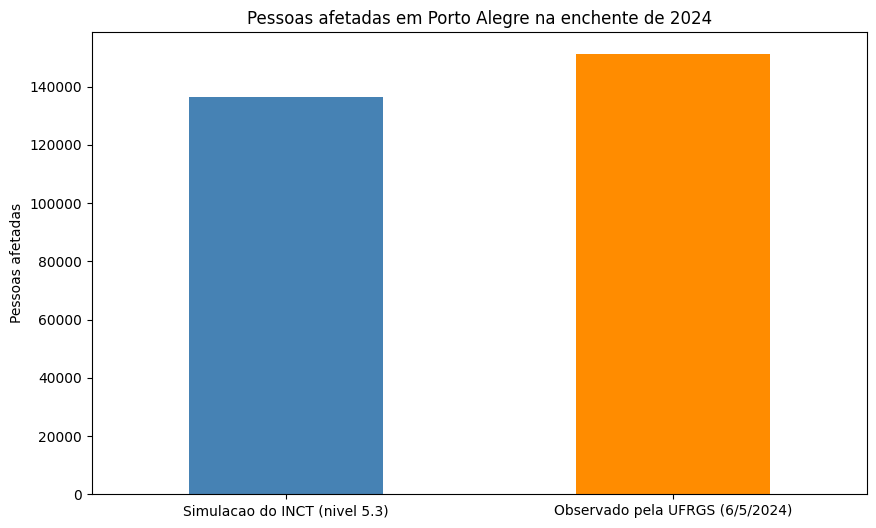

In [13]:
# Gráfico 9: pessoas afetadas em Porto Alegre na enchente de 2024, pela simulação do INCT e pela observação da UFRGS
# A UFRGS usou a mancha de água observada em 6 de maio de 2024, um dia depois do pico de 5,35 metros
porto_alegre_ufrgs = ufrgs[ufrgs["NM_MUN"] == "Porto Alegre"]["Pessoas_afetadas"].iloc[0]
porto_alegre_inct = pessoas_por_nivel.loc[5.3]

comparacao = pd.Series([porto_alegre_inct, porto_alegre_ufrgs], index=["Simulacao do INCT (nivel 5.3)", "Observado pela UFRGS (6/5/2024)"])
print(comparacao)

# Mostra em qual nível da simulação o número de pessoas chega perto do valor observado pela UFRGS
print(pessoas_por_nivel.loc[5.5:5.8])

plt.figure(figsize=(10,6))
comparacao.plot(kind="bar", color=["steelblue", "darkorange"])
plt.title("Pessoas afetadas em Porto Alegre na enchente de 2024")
plt.ylabel("Pessoas afetadas")
plt.xticks(rotation=0)
plt.show()

# O que o gráfico mostra: para a enchente de 2024, a simulação do INCT no nível 5,3 estima cerca de 136 mil pessoas afetadas
# em Porto Alegre, e a UFRGS, com a mancha de água observada por satélite, chegou a cerca de 151 mil.
# A simulação só chega a esse número entre os níveis 5,6 e 5,7. As duas bases têm a mesma ordem de grandeza,
# mas a diferença mostra que a simulação pode estar subestimando um pouco o impacto real.